
# Post-processing: plot and analyze the results

In [1]:
import meshio
import numpy as np
import glob, os

import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.colors import LogNorm
from matplotlib import mathtext
import math

#Plot Setup
font = {'size':14}
plt.rc('font', **font)
plt.rc('font', family='serif')
plt.rc('text', usetex=False)

In [2]:
# Sort files

snapshot_dir = 'large_N/'
files = sorted(glob.glob(snapshot_dir + "*.vtu"), key=len)
print(files)

# Just save figures, don't display them
import matplotlib
matplotlib.use('Agg')

for file in files:
    
    print(file)
    
    # Import vtu data
    mesh = meshio.read( file )

#    print(mesh.point_data_to_sets)
#    print(np.shape(mesh.point_data["x"]))

    # Extract Fields
    x = mesh.point_data["x"][:,0]
    y = mesh.point_data["x"][:,1]
    density = mesh.point_data["density"][:,0]
#    print(np.shape(x), np.shape(density))
    
    # Plot
    fig = plt.figure(figsize = (7, 6))
    plt.scatter(x, y, marker=".", s=90, c=density, edgecolors="k", norm=LogNorm(0.95,7), cmap='jet' )
    plt.colorbar()
    #plt.tight_layout()
#    plt.show()

#    fig.savefig(file + ".pdf", bbox_inches='tight', dpi=200)
    fig.savefig( file + ".jpeg", bbox_inches='tight')
    
# The images can be converted into an animation via ImageMagick
#!convert -delay 10 -loop 0 *.png animation.gif

['large_N/particles-0-rank-0.vtu', 'large_N/particles-1-rank-0.vtu', 'large_N/particles-2-rank-0.vtu', 'large_N/particles-3-rank-0.vtu', 'large_N/particles-4-rank-0.vtu', 'large_N/particles-5-rank-0.vtu', 'large_N/particles-6-rank-0.vtu', 'large_N/particles-7-rank-0.vtu', 'large_N/particles-8-rank-0.vtu', 'large_N/particles-9-rank-0.vtu', 'large_N/particles-10-rank-0.vtu', 'large_N/particles-11-rank-0.vtu', 'large_N/particles-12-rank-0.vtu', 'large_N/particles-13-rank-0.vtu', 'large_N/particles-14-rank-0.vtu', 'large_N/particles-15-rank-0.vtu', 'large_N/particles-16-rank-0.vtu', 'large_N/particles-17-rank-0.vtu', 'large_N/particles-18-rank-0.vtu', 'large_N/particles-19-rank-0.vtu', 'large_N/particles-20-rank-0.vtu', 'large_N/particles-21-rank-0.vtu', 'large_N/particles-22-rank-0.vtu', 'large_N/particles-23-rank-0.vtu', 'large_N/particles-24-rank-0.vtu', 'large_N/particles-25-rank-0.vtu', 'large_N/particles-26-rank-0.vtu', 'large_N/particles-27-rank-0.vtu', 'large_N/particles-28-rank-0.

KeyboardInterrupt: 

In [ ]:
#!convert -delay 10 -loop 0 sedov_blast_u_2e-1/*.jpeg animation.gif

## Analytical solution (from Swift)

Computes the analytical solution of the 2D Sedov blast wave.

In [2]:
from scipy.special import gamma as Gamma

def calc_a(g, nu=3):
    """ 
    exponents of the polynomials of the sedov solution
    g - the polytropic gamma
    nu - the dimension
    """
    a = [0] * 8

    a[0] = 2.0 / (nu + 2)
    a[2] = (1 - g) / (2 * (g - 1) + nu)
    a[3] = nu / (2 * (g - 1) + nu)
    a[5] = 2 / (g - 2)
    a[6] = g / (2 * (g - 1) + nu)

    a[1] = (((nu + 2) * g) / (2.0 + nu * (g - 1.0))) * (
        (2.0 * nu * (2.0 - g)) / (g * (nu + 2.0) ** 2) - a[2]
    )
    a[4] = a[1] * (nu + 2) / (2 - g)
    a[7] = (2 + nu * (g - 1)) * a[1] / (nu * (2 - g))
    return a

def calc_beta(v, g, nu=3):
    """ 
    beta values for the sedov solution (coefficients of the polynomials of the similarity variables) 
    v - the similarity variable
    g - the polytropic gamma
    nu- the dimension
    """

    beta = (
        (nu + 2)
        * (g + 1)
        * np.array(
            (
                0.25,
                (g / (g - 1)) * 0.5,
                -(2 + nu * (g - 1))
                / 2.0
                / ((nu + 2) * (g + 1) - 2 * (2 + nu * (g - 1))),
                -0.5 / (g - 1),
            ),
        )
    )

    beta = np.outer(beta, v)

    beta += (g + 1) * np.array(
        (
            0.0,
            -1.0 / (g - 1),
            (nu + 2) / ((nu + 2) * (g + 1) - 2.0 * (2 + nu * (g - 1))),
            1.0 / (g - 1),
        ),
    ).reshape((4, 1))

    return beta


def sedov(t, E0, rho0, g, n=1000, nu=3):
    """ 
    solve the sedov problem
    t - the time
    E0 - the initial energy
    rho0 - the initial density
    n - number of points (10000)
    nu - the dimension
    g - the polytropic gas gamma
    """
    # the similarity variable
    v_min = 2.0 / ((nu + 2) * g)
    v_max = 4.0 / ((nu + 2) * (g + 1))

    v = v_min + np.arange(n) * (v_max - v_min) / (n - 1.0)

    a = calc_a(g, nu)
    beta = calc_beta(v, g=g, nu=nu)
    lbeta = np.log(beta)

    r = np.exp(-a[0] * lbeta[0] - a[2] * lbeta[1] - a[1] * lbeta[2])
    rho = ((g + 1.0) / (g - 1.0)) * np.exp(
        a[3] * lbeta[1] + a[5] * lbeta[3] + a[4] * lbeta[2]
    )
    p = np.exp(nu * a[0] * lbeta[0] + (a[5] + 1) * lbeta[3] + (a[4] - 2 * a[1]) * lbeta[2])
    u = beta[0] * r * 4.0 / ((g + 1) * (nu + 2))
    p *= 8.0 / ((g + 1) * (nu + 2) * (nu + 2))

    # we have to take extra care at v=v_min, since this can be a special point.
    # It is not a singularity, however, the gradients of our variables (wrt v) are.
    # r -> 0, u -> 0, rho -> 0, p-> constant

    u[0] = 0.0
    rho[0] = 0.0
    r[0] = 0.0
    p[0] = p[1]

    # volume of an n-sphere
    vol = (np.pi ** (nu / 2.0) / Gamma(nu / 2.0 + 1)) * np.power(r, nu)

    # note we choose to evaluate the integral in this way because the
    # volumes of the first few elements (i.e near v=vmin) are shrinking
    # very slowly, so we dramatically improve the error convergence by
    # finding the volumes exactly. This is most important for the
    # pressure integral, as this is on the order of the volume.

    # (dimensionless) energy of the model solution
    de = rho * u * u * 0.5 + p / (g - 1)
    # integrate (trapezium rule)
    q = np.inner(de[1:] + de[:-1], np.diff(vol)) * 0.5

    # the factor to convert to this particular problem
    fac = (q * (t ** nu) * rho0 / E0) ** (-1.0 / (nu + 2))

    # shock speed
    shock_speed = fac * (2.0 / (nu + 2))
    rho_s = ((g + 1) / (g - 1)) * rho0
    r_s = shock_speed * t * (nu + 2) / 2.0
    p_s = (2.0 * rho0 * shock_speed * shock_speed) / (g + 1)
    u_s = (2.0 * shock_speed) / (g + 1)

    r *= fac * t
    u *= fac
    p *= fac * fac * rho0
    rho *= rho0
    return r, p, rho, u, r_s, p_s, rho_s, u_s, shock_speed

## Radial profiles

<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 14400
  Number of cells:
    vertex: 14400
  Point data: x, cut-off-radius, association, v, a, density, pressure, u, mass, smoothingLength, smoothingLengthPrevious, Omega, rhoDot, rho_dh, Ncount, wcount, wcount_dh, soundSpeed, hasConverged, rot_v, div_v, div_v_dt, div_v_prev_step, alpha_AV, v_sig_AV, alpha_AV_max_ngb, balsara, laplace_u, alpha_D>
** 60 ** particles found with this filter.


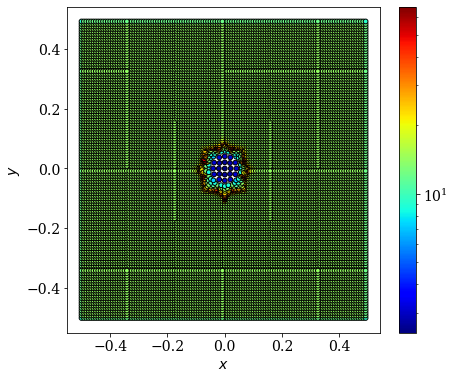

In [126]:
# Import file
#snapshot_dir = 'large_N_fixed_laplace_u/'
#snapshot_dir = 'u_ini_1_dt_1e-3/'
snapshot_dir = ''
files = sorted(glob.glob(snapshot_dir + "*.vtu"), key=len)
snapshot_number = 20

mesh = meshio.read( files[snapshot_number] )
print(mesh.point_data_to_sets)

# Extract Fields
x = mesh.point_data["x"][:,0] - 0.5
y = mesh.point_data["x"][:,1] - 0.5
density = mesh.point_data["density"][:,0]
pressure= mesh.point_data["pressure"][:,0]
energy  = mesh.point_data["u"][:,0]
vel_x   = mesh.point_data["v"][:,0] 
vel_y   = mesh.point_data["v"][:,1] 
mass    = mesh.point_data["mass"][:,0]

# Filter by position
x_mask = np.greater_equal( x, 0 )
y_min = -1e-3
y_max = 1e-3
y_mask = np.less_equal(y, y_max)
y_mask = y_mask & np.greater_equal(y, y_min)
pos_mask = x_mask & y_mask

x_line = x[pos_mask]
y_line = y[pos_mask]
density_x = density[pos_mask]
pressure_x= pressure[pos_mask]
energy_x  = energy[pos_mask]
vel_x_line = vel_x[pos_mask]
vel_y_line = vel_y[pos_mask]

#print(x.shape, density.shape, x_line.shape, density_x.shape)
print('** ' + str(len(x_line)) + ' ** particles found with this filter.')

# Plot
fig = plt.figure(figsize = (7, 6))
plt.scatter(x, y, marker=".", s=90, c=density, edgecolors="k", norm=LogNorm(density.min(),density.max()), cmap='jet' )
plt.colorbar()
plt.xlabel(r'$x$')
plt.ylabel(r'$y$')
#plt.tight_layout()
plt.show()

In [127]:
# Parameters
time_step_sim = 1e-3
snapshot_rate = 10
N_part_blast  = 21

time = snapshot_number*snapshot_rate*time_step_sim
rho_0 = 14.0                        # Background Density
P_0 = 1.0e-6                       # Background Pressure
u_0 = 1.0
E_0 = N_part_blast*mass[0]*u_0     # Total Energy of the explosion
gas_gamma = 5.0/3.0                # Gas polytropic index

# The main properties of the solution
r_s, P_s, rho_s, v_s, r_shock, _, _, _, _ = sedov(time, E_0, rho_0, gas_gamma, 2000, 2)

# Append points for after the shock
r_s = np.insert(r_s, np.size(r_s), [r_shock, r_shock * 1.5])
rho_s = np.insert(rho_s, np.size(rho_s), [rho_0, rho_0])
P_s = np.insert(P_s, np.size(P_s), [P_0, P_0])
v_s = np.insert(v_s, np.size(v_s), [0, 0])

# Additional arrays
u_s = P_s / (rho_s * (gas_gamma - 1.0))  # internal energy
s_s = P_s / rho_s ** gas_gamma           # entropic function

/tmp/ipykernel_292089/3350837773.py:23: RuntimeWarning: divide by zero encountered in true_divide
  u_s = P_s / (rho_s * (gas_gamma - 1.0))  # internal energy
/tmp/ipykernel_292089/3350837773.py:24: RuntimeWarning: divide by zero encountered in true_divide
  s_s = P_s / rho_s ** gas_gamma           # entropic function


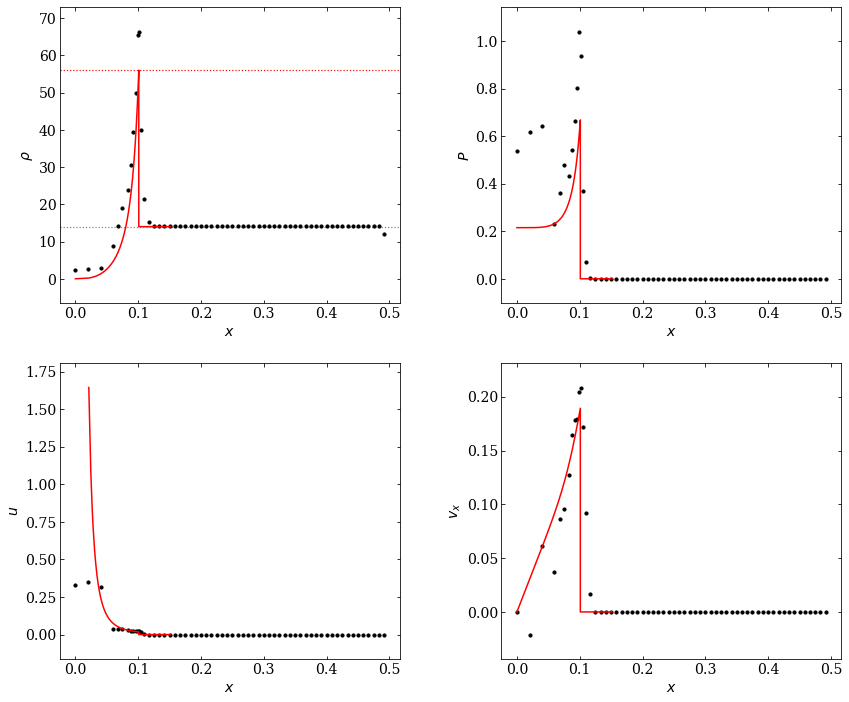

In [128]:
# Plot radial profiles
fig = plt.figure(figsize=(14, 12)) 
gs = gridspec.GridSpec(2,2, height_ratios=[1,1], wspace=0.3) 

ax0 = plt.subplot(gs[0])
plt.plot(r_s,rho_s, c='r')
plt.scatter(x_line, density_x, s=10, c='k')
plt.xlabel(r'$x$')
plt.ylabel(r'$\rho$')
plt.margins(0.05, 0.1)
plt.tick_params(direction='in', top=True, right=True)
plt.axhline(rho_0, c='gray', ls=':', lw=1.2,zorder=-49 )
plt.axhline( (5./3.+1.)/(5./3.-1.)*rho_0, c='r', ls=':', lw=1.2,zorder=-49 )

ax1 = plt.subplot(gs[1])
plt.plot(r_s, P_s, c='r')
plt.scatter(x_line, pressure_x, s=10, c='k')
plt.xlabel(r'$x$')
plt.ylabel(r'$P$')
plt.margins(0.05, 0.1)
plt.tick_params(direction='in', top=True, right=True)

ax2 = plt.subplot(gs[2])
plt.plot(r_s, u_s, c='r')
plt.scatter(x_line, energy_x, s=10, c='k')
plt.xlabel(r'$x$')
plt.ylabel(r'$u$')
plt.margins(0.05, 0.1)
plt.tick_params(direction='in', top=True, right=True)

ax3 = plt.subplot(gs[3])
plt.plot(r_s, v_s, c='r')
plt.scatter(x_line, vel_x_line, s=10, c='k')
plt.xlabel(r'$x$')
plt.ylabel(r'$v_x$')
plt.margins(0.05, 0.1)
plt.tick_params(direction='in', top=True, right=True)

plt.show()
plt.close()

## pressure_x

In [92]:
energy_x

array([1.50000e-06, 1.50007e-06, 1.50808e-06, 1.49688e-06, 1.38291e-06,
       4.54025e-03, 2.10955e-03, 4.03814e-04, 7.58494e-06, 1.50143e-06,
       1.92451e-01, 1.19221e-02, 1.26507e-02, 9.03445e-03, 7.10500e-03,
       6.36528e-03], dtype=float32)

In [188]:
density_x

array([0.999233, 0.999235, 0.999227, 0.992128, 0.734043, 0.999235,
       0.999233, 0.999233, 0.999233, 0.999233, 0.802513, 0.939971,
       1.04493 , 1.01798 , 1.0009  , 0.999296], dtype=float32)

In [115]:
x_line

array([0.34375   , 0.375     , 0.40625   , 0.4375    , 0.46875298,
       0.18776798, 0.21875203, 0.25      , 0.28125   , 0.3125    ,
       0.07842201, 0.12876499, 0.14224398, 0.16056103, 0.11189902],
      dtype=float32)

In [120]:
density_x

array([1.00003 , 0.999999, 1.00002 , 0.999778, 0.852584, 3.73858 ,
       1.41088 , 1.0648  , 1.00386 , 0.456492, 0.916027, 3.41434 ,
       0.164136, 0.583106, 1.84547 , 2.41849 ], dtype=float32)

In [109]:
density_x[np.where(x_line==x_line.min())]

array([3.73858], dtype=float32)

In [62]:
vel_x_line

array([ 7.10098e-17,  2.13572e-11, -1.78107e-09, -1.99656e-06,
        2.05755e-05,  6.29392e-02,  1.18166e-02,  2.60688e-04,
        3.84399e-07,  9.06144e-11,  2.72643e-02,  1.18389e-01,
        1.07463e-01,  1.02757e-07, -3.47690e-03,  9.71854e-02],
      dtype=float32)